# 03 · Nhận diện bài hát bằng "dấu vân tay" âm thanh (kiểu Shazam)

**Câu hỏi của notebook:** cho một đoạn thu ngắn (2 đến 10 giây), có thể bị ồn, bị nén MP3, hay lẫn nhạc khác, làm sao tìm ra đó là **bài nào trong kho nhạc**, và chính xác tới đâu?

**Khác gì notebook 02?**

| | Notebook 02 (đoán mood) | Notebook 03 (nhận diện bài) |
|---|---|---|
| Bài toán | **phân loại**: đoán nhãn cho bài *chưa từng thấy* | **tra cứu**: tìm đúng bài *đã có trong kho* |
| Có học từ dữ liệu không | có (Logistic Regression, Random Forest) | **không** có mô hình, không huấn luyện |
| Đặc trưng | 93 con số tóm tắt cả đoạn 30 s | hàng chục nghìn **mã băm** từ các đỉnh nổi bật của phổ |
| Đáp án | mơ hồ (nhãn mood do người gắn, chủ quan) | **duy nhất và rõ ràng** (đúng bài hoặc sai bài) |
| Cách đo | macro-recall so với đoán mò, chia theo artist | top-1 theo độ dài đoạn và loại nhiễu, ngưỡng từ chối bài lạ |

**Vì sao làm bài này (nói thật):**
1. Đáp án đúng/sai rõ ràng nên **đánh giá không mơ hồ** như mood. Ở notebook 02 ta phải rất cẩn thận (chia theo artist, so với baseline thể loại) vì nhãn mood nhiễu. Ở đây không cần.
2. Dùng **cùng loại dữ liệu (spectrogram) nhưng ý tưởng ngược hẳn**: notebook 02 *nén cả đoạn* thành vài chục số rồi để mô hình học; notebook 03 *giữ lại vài điểm nổi bật nhất* và coi chúng là chữ ký để tra bảng. So sánh hai cách giúp hiểu khi nào cần học máy, khi nào không.
3. Có nhiều thứ để **tự đặt thí nghiệm và giải thích**: nhiễu gì làm hỏng, đoạn ngắn tới đâu thì chịu được, tham số nào quan trọng, kho lớn lên thì sao. Đó là kiểu "tạo bài toán, giải quyết, giải thích" mà môn yêu cầu.

**Luồng làm việc**
1. Ý tưởng và từng bước của thuật toán: spectrogram, **đỉnh** (constellation), **cặp đỉnh → hash**.
2. Xây **chỉ mục** (bảng tra) cho cả kho nhạc.
3. Truy vấn: **bỏ phiếu theo độ lệch thời gian** để chọn bài.
4. Thí nghiệm chính: độ chính xác theo độ dài đoạn và loại nhiễu, bài lạ ngoài kho, giới hạn của phương pháp.
5. Thay đổi tham số (ablation) và kho lớn dần.
6. Thử trọn vẹn một ví dụ, so sánh với notebook 02, nói thật về hạn chế.

*Tài liệu gốc của ý tưởng: Avery Wang (2003), "An Industrial-Strength Audio Search Algorithm", ISMIR. Bản cài đặt trong notebook này là **bản đơn giản hóa** để dễ hiểu, không phải bản của Shazam.*

In [1]:
import os
import time
import io
import pickle
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import librosa
import soundfile as sf
from scipy.ndimage import maximum_filter
from scipy.signal import butter, sosfilt
from joblib import Parallel, delayed
from IPython.display import display

warnings.filterwarnings("ignore")

# ============ CẤU HÌNH — chỉnh ở đây ============
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
AUDIO_DIR = Path(os.environ.get("JAMENDO_AUDIO_DIR", ROOT / "data" / "audio-low")).expanduser()
INDEX_CSV = ROOT / "data" / "index_mood.csv"      # danh sách 1.020 bài, tạo bởi notebook 01
CACHE_DIR = ROOT / "data" / "fp_cache"            # kết quả trung gian (nằm trong data/ nên không bị commit)
CACHE_DIR.mkdir(parents=True, exist_ok=True)

SR, N_FFT, HOP = 11025, 1024, 256   # 11.025 kHz: nhạc vẫn rõ tới ~5.5 kHz; mỗi khung dài 256 mẫu = 23 ms
PARAMS = dict(nf=21, nt=41, floor=0.0, K=5, dt_max=63, df_max=200)   # tham số mặc định của thuật toán (giải thích ở phần 1)
N_QUERIES = 200                      # số đoạn truy vấn cho mỗi thí nghiệm chính
QUERY_LENGTHS = [2, 5, 10]           # độ dài đoạn truy vấn (giây)
MAX_CATALOG = None                   # đặt vd 100 để chạy thử nhanh; None = cả 1.020 bài
N_JOBS = -1                          # -1 = dùng mọi nhân CPU
SEED = 0                             # cố định ngẫu nhiên để lặp lại được
# ================================================

plt.rcParams["figure.dpi"] = 110
PARAMS_TAG = "_".join(f"{k}{v}" for k, v in PARAMS.items())
print("ROOT =", ROOT)
print("AUDIO_DIR =", AUDIO_DIR)
print("Khung thời gian: 1 khung =", round(1000 * HOP / SR, 1), "ms | 1 ô tần số =", round(SR / N_FFT, 2), "Hz")


def cached(name, fn):
    # Tính một lần rồi lưu đĩa; chạy lại notebook thì đọc từ đĩa. Xóa thư mục data/fp_cache để tính lại từ đầu.
    path = CACHE_DIR / f"{name}.pkl"
    if path.exists():
        with open(path, "rb") as f:
            return pickle.load(f)
    out = fn()
    with open(path, "wb") as f:
        pickle.dump(out, f)
    return out

ROOT = /sessions/rcw-019jud4jbwogktyxr7utksgc/work/fp/run
AUDIO_DIR = /sessions/rcw-019jud4jbwogktyxr7utksgc/mnt/audio-low
Khung thời gian: 1 khung = 23.2 ms | 1 ô tần số = 10.77 Hz


---
## Phần 0 — Kho nhạc

**Kho (catalog)** là các bài ta lập chỉ mục: 1.020 bài đã dùng ở notebook 02 (đọc từ `index_mood.csv`). Ở đây ta **không dùng nhãn mood** gì cả; chỉ cần biết mỗi bài là bài nào.

Trong thư mục audio còn khoảng 970 bài **không nằm trong kho**. Ta giữ chúng riêng, để sau này kiểm tra xem hệ thống phản ứng thế nào khi nghe một bài **lạ**.

Thứ tự bài trong kho được **xáo ngẫu nhiên một lần** (cố định `SEED`), để lấy "100 bài đầu" hay "300 bài đầu" cũng là mẫu ngẫu nhiên.

In [2]:
def audio_path(rel_path, audio_dir=AUDIO_DIR):
    # 'PATH' trong TSV là '48/948.mp3'; file audio-low thật là '48/948.low.mp3'.
    return Path(audio_dir) / str(rel_path).replace(".mp3", ".low.mp3")


if not INDEX_CSV.exists():
    raise FileNotFoundError(f"Chưa có {INDEX_CSV}. Hãy chạy hết notebook 01 trước.")

cat_df = pd.read_csv(INDEX_CSV, dtype={"track_id": str})
cat_df["file"] = [audio_path(p) for p in cat_df["path"]]
cat_df = cat_df[cat_df["file"].map(Path.exists)].sample(frac=1, random_state=SEED).reset_index(drop=True)
if MAX_CATALOG:
    cat_df = cat_df.head(MAX_CATALOG)

CAT = list(cat_df["file"])                      # đường dẫn file; vị trí trong danh sách = "mã bài" nội bộ
DUR = cat_df["duration"].to_numpy()             # độ dài (giây)
UNKNOWN = sorted(p for p in AUDIO_DIR.rglob("*.low.mp3") if p not in set(CAT))   # bài ngoài kho

print(f"Kho: {len(CAT)} bài | tổng {DUR.sum() / 3600:.1f} giờ | độ dài trung vị {np.median(DUR):.0f} s")
print(f"Bài ngoài kho (để thử bài lạ): {len(UNKNOWN)}")
cat_df[["track_id", "artist_id", "duration"]].head(3)

Kho: 1020 bài | tổng 62.2 giờ | độ dài trung vị 203 s
Bài ngoài kho (để thử bài lạ): 971


,track_id,artist_id,duration
0,track_1420504,artist_497198,137.6
1,track_0080500,artist_001935,129.3
2,track_0316206,artist_349009,216.1


---
## Phần 1 — Thuật toán từng bước

### 1.1. Vì sao không so sánh thẳng âm thanh với nhau

Cách ngây thơ nhất: lấy đoạn thu, trượt dọc từng bài trong kho, bài nào giống nhất thì chọn. Cách này hỏng vì:
- **Nặng:** kho có hàng triệu bài, mỗi bài hàng triệu mẫu; so khớp từng mẫu là bất khả thi.
- **Mong manh:** nhiễu, nén MP3, âm lượng khác, micro điện thoại làm **mọi con số** thay đổi, dù tai người nghe vẫn nhận ra ngay bài.

Ý tưởng của Shazam: chỉ giữ lại **những điểm nổi bật nhất** của phổ (ít bị nhiễu làm mất), biến chúng thành các **mã số** rồi tra bảng như tra từ điển. Mỗi bước dưới đây tương ứng một ý.

### 1.2. Đọc âm thanh và tính spectrogram

Giống notebook 01, nhưng có hai thay đổi:
- Dùng $f_s = 11025$ Hz (không phải 22050) để nhẹ hơn; nhạc vẫn rõ tới khoảng 5,5 kHz.
- **Chuẩn hóa theo RMS** trước khi tính phổ: chia tín hiệu cho căn bậc hai của năng lượng trung bình. Nhờ vậy dù đoạn thu to hay nhỏ, thang dB của phổ gần như cố định, và ngưỡng ta đặt (`floor`) có nghĩa nhất quán giữa một bài đầy đủ và một đoạn 3 giây.

Phổ tính bằng dB: $L(f, t) = 20 \log_{10} |X(f,t)|$.

In [3]:
def load_audio(path, offset=0.0, duration=None):
    y, _ = librosa.load(path, sr=SR, mono=True, offset=offset, duration=duration)
    return y


def spectrogram_db(y):
    y = y / (np.sqrt(np.mean(y ** 2)) + 1e-9)               # chuẩn hóa RMS -> bất biến âm lượng
    S = np.abs(librosa.stft(y, n_fft=N_FFT, hop_length=HOP))
    return 20 * np.log10(S + 1e-9)                          # dB, hình (513 ô tần số, số khung)


demo_idx = 0
y_demo = load_audio(CAT[demo_idx], offset=60, duration=10)
L_demo = spectrogram_db(y_demo)
print(f"Đoạn demo: {len(y_demo)} mẫu = {len(y_demo) / SR:.1f} s | phổ có hình {L_demo.shape} (tần số x khung)")

Đoạn demo: 110250 mẫu = 10.0 s | phổ có hình (513, 431) (tần số x khung)


### 1.3. Đỉnh của phổ (constellation map)

Một **đỉnh** là điểm $(f, t)$ có năng lượng **lớn nhất trong một vùng lân cận** quanh nó (vùng hình chữ nhật `nf` ô tần số × `nt` khung thời gian) **và** cao hơn ngưỡng `floor`. Ta dùng `maximum_filter` của SciPy: với mỗi ô, nó cho biết giá trị lớn nhất trong vùng lân cận; ô nào bằng đúng giá trị đó là đỉnh.

Vì sao đỉnh bền với nhiễu? Nhiễu thêm một lớp năng lượng đều và nhỏ lên toàn phổ, nhưng những điểm *nổi hẳn lên* so với xung quanh (một nốt, một tiếng trống) vẫn nổi. Còn những điểm lưng chừng thì đỉnh có thể đổi chỗ, nên ta chấp nhận mất một phần đỉnh; phần còn sống sót đủ để nhận ra bài.

Tham số `nf`, `nt` chỉnh **mật độ đỉnh**: vùng lân cận càng rộng thì đỉnh càng thưa. Thưa thì chỉ mục nhỏ và ít nhiễu hơn, nhưng đoạn ngắn có ít đỉnh để dựa vào (xem phần 5).

229 đỉnh trong 10 s = 22.9 đỉnh/giây (so với 221103 ô của phổ: giữ lại 0.10%)


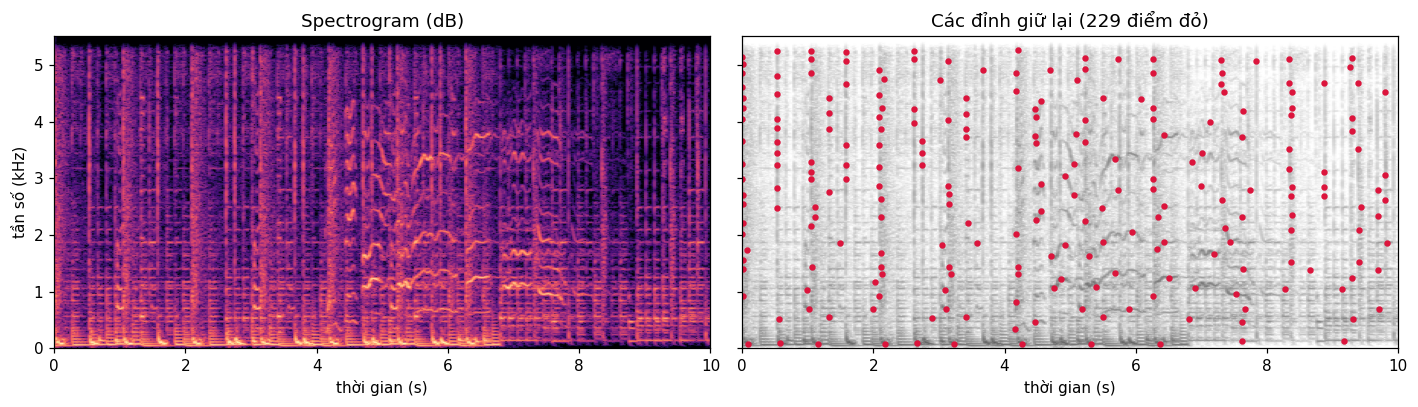

In [4]:
def find_peaks(L, nf, nt, floor):
    local_max = maximum_filter(L, size=(nf, nt), mode="constant", cval=-200)
    f, t = np.nonzero((L == local_max) & (L > floor))      # ô bằng cực đại cục bộ và đủ lớn
    order = np.lexsort((f, t))                              # sắp theo thời gian, rồi theo tần số
    return f[order], t[order]


pk_f, pk_t = find_peaks(L_demo, PARAMS["nf"], PARAMS["nt"], PARAMS["floor"])
dur_demo = len(y_demo) / SR
print(f"{len(pk_f)} đỉnh trong {dur_demo:.0f} s = {len(pk_f) / dur_demo:.1f} đỉnh/giây "
      f"(so với {L_demo.size} ô của phổ: giữ lại {100 * len(pk_f) / L_demo.size:.2f}%)")

fig, axes = plt.subplots(1, 2, figsize=(13, 3.8), sharey=True)
ext = [0, dur_demo, 0, SR / 2000]
vmin, vmax = np.percentile(L_demo, 5), L_demo.max()
axes[0].imshow(L_demo, origin="lower", aspect="auto", extent=ext, cmap="magma", vmin=vmin, vmax=vmax)
axes[0].set_title("Spectrogram (dB)")
axes[1].imshow(L_demo, origin="lower", aspect="auto", extent=ext, cmap="Greys", vmin=vmin, vmax=vmax + 30)
axes[1].scatter(pk_t * HOP / SR, pk_f * SR / N_FFT / 1000, s=10, c="crimson")
axes[1].set_title(f"Các đỉnh giữ lại ({len(pk_f)} điểm đỏ)")
for ax in axes:
    ax.set_xlabel("thời gian (s)")
axes[0].set_ylabel("tần số (kHz)")
plt.tight_layout(); plt.show()

**Cách đọc hình:** bên trái là phổ đầy đủ (hàng trăm nghìn ô). Bên phải chỉ còn vài trăm chấm đỏ, **trông như bản đồ sao**, nên người ta gọi là *constellation map*. Toàn bộ thông tin dùng để nhận diện nằm trong những chấm đỏ này; phần còn lại bị bỏ.

### 1.4. Từ đỉnh thành mã băm (hash): ghép **cặp** đỉnh

Một đỉnh đơn lẻ chỉ cho ta một con số tần số (khoảng 512 giá trị). Con số đó xuất hiện ở **mọi bài**, nên tra bảng sẽ ra hàng nghìn kết quả vô nghĩa. Ta cần mã **đặc trưng hơn**: ghép hai đỉnh gần nhau thành **cặp**, mã hóa:

$$\text{hash} = (f_1,\; f_2,\; \Delta t), \qquad \Delta t = t_2 - t_1$$

- $f_1, f_2$: ô tần số của hai đỉnh (9 bit mỗi cái, 0 đến 511).
- $\Delta t$: khoảng cách thời gian giữa hai đỉnh, tính theo khung (6 bit, 0 đến 63).
- Gộp lại là số nguyên **24 bit**, có $2^{24} \approx 16{,}7$ triệu giá trị có thể, đặc trưng hơn đỉnh đơn khoảng **33.000 lần**.

Hash **không chứa thời gian tuyệt đối** của đoạn, chỉ chứa khoảng cách *tương đối* giữa hai đỉnh. Nhờ vậy đoạn thu bắt đầu ở giây nào cũng cho **cùng hash** với đoạn tương ứng trong bài gốc. Còn thời điểm tuyệt đối $t_1$ ta cất riêng để dùng ở bước bỏ phiếu (phần 3).

Cách ghép trong bản này (đơn giản hóa): **mỗi đỉnh ghép với `K` đỉnh kế tiếp theo thời gian**, miễn là cách không quá `dt_max` khung và lệch tần số không quá `df_max` ô. Nếu `K = 5` thì mỗi đỉnh sinh tối đa 5 hash.

481 hash cho 10 s = 48 hash/giây
Ví dụ 3 hash đầu:
  hash=  5276097 = (f1=161, f2=7, dt=1)  tại khung t1=3 (0.07 s)
  hash=  1573441 = (f1=48, f2=9, dt=1)  tại khung t1=24 (0.56 s)
  hash=   301074 = (f1=9, f2=96, dt=18)  tại khung t1=25 (0.58 s)


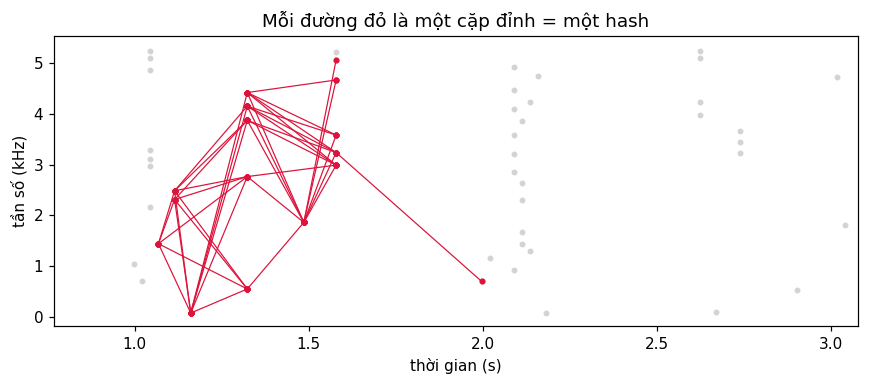

In [5]:
def make_hashes(f, t, K, dt_max, df_max):
    # Trả về (hash 24-bit, thời điểm đỉnh thứ nhất t1) cho mọi cặp hợp lệ.
    hashes, times = [], []
    for k in range(1, K + 1):                              # ghép đỉnh i với đỉnh i+k
        if len(f) <= k:
            break
        f1, t1, f2, t2 = f[:-k], t[:-k], f[k:], t[k:]
        dt = t2 - t1
        ok = (dt >= 1) & (dt <= dt_max) & (np.abs(f2.astype(int) - f1) <= df_max)
        h = (np.minimum(f1[ok], 511).astype(np.uint32) << 15) \
            | (np.minimum(f2[ok], 511).astype(np.uint32) << 6) \
            | dt[ok].astype(np.uint32)
        hashes.append(h)
        times.append(t1[ok])
    if not hashes:
        return np.empty(0, np.uint32), np.empty(0, np.int32)
    return np.concatenate(hashes), np.concatenate(times).astype(np.int32)


def fingerprint(y, nf, nt, floor, K, dt_max, df_max):
    # Toàn bộ quy trình: tín hiệu -> phổ -> đỉnh -> hash.
    L = spectrogram_db(y)
    f, t = find_peaks(L, nf, nt, floor)
    return make_hashes(f, t, K, dt_max, df_max)


h_demo, t_demo = fingerprint(y_demo, **PARAMS)
print(f"{len(h_demo)} hash cho {dur_demo:.0f} s = {len(h_demo) / dur_demo:.0f} hash/giây")
print("Ví dụ 3 hash đầu:")
for h, t in list(zip(h_demo[:3], t_demo[:3])):
    print(f"  hash={h:>9d} = (f1={h >> 15}, f2={(h >> 6) & 511}, dt={h & 63})  tại khung t1={t} ({t * HOP / SR:.2f} s)")

# Vẽ vài cặp để thấy "cặp đỉnh" là gì
sel = slice(40, 52)
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.scatter(pk_t * HOP / SR, pk_f * SR / N_FFT / 1000, s=8, c="lightgray")
for i in range(40, 52):
    for k in range(1, PARAMS["K"] + 1):
        j = i + k
        dt = pk_t[j] - pk_t[i]
        if 1 <= dt <= PARAMS["dt_max"]:
            ax.plot(pk_t[[i, j]] * HOP / SR, pk_f[[i, j]] * SR / N_FFT / 1000, "-o", ms=3, lw=0.8, c="crimson")
ax.set_xlim(pk_t[40] * HOP / SR - 0.3, pk_t[52] * HOP / SR + 1.5)
ax.set_xlabel("thời gian (s)"); ax.set_ylabel("tần số (kHz)")
ax.set_title("Mỗi đường đỏ là một cặp đỉnh = một hash")
plt.tight_layout(); plt.show()

### 1.5. Hash sống sót thế nào khi có nhiễu?

Trước khi xây cả hệ thống, kiểm tra ý tưởng bằng một phép thử trực tiếp: lấy một đoạn 5 s từ một bài, làm hỏng nó theo nhiều cách, rồi hỏi: **bao nhiêu phần trăm hash của đoạn hỏng vẫn có mặt trong tập hash của bài gốc?** (Chưa xét vị trí thời gian, chỉ xét có hash đó hay không.) Để so, ta cũng đếm tỷ lệ này với **một bài khác ngẫu nhiên**: đó là mức "trùng hợp".

Các kiểu làm hỏng (dùng lại ở phần 4):
- **Ồn trắng** ở mức tín hiệu/nhiễu (SNR) cho trước: $\text{SNR} = 10\log_{10}(P_{\text{tín hiệu}} / P_{\text{nhiễu}})$. SNR 0 dB nghĩa là nhiễu to bằng nhạc.
- **Nén MP3** thêm một lần ở bitrate rất thấp (khoảng 30 đến 40 kbps).
- **Micro điện thoại**: chỉ giữ dải 300 đến 3400 Hz (lọc thông dải).
- **Nhạc nền**: trộn thêm một bài khác ở SNR cho trước.
- **Đổi tốc độ**: phát nhanh hơn $x\%$ (cao độ đổi theo).

In [6]:
def add_noise(y, snr_db, rng):
    noise = rng.standard_normal(len(y)) * np.sqrt(np.mean(y ** 2) / 10 ** (snr_db / 10))
    return (y + noise).astype(np.float32)


def mix_music(y, other, snr_db):
    other = np.pad(other, (0, max(0, len(y) - len(other))))[: len(y)]
    gain = np.sqrt(np.mean(y ** 2) / (np.mean(other ** 2) + 1e-12) / 10 ** (snr_db / 10))
    return (y + gain * other).astype(np.float32)


def phone_filter(y, lo=300, hi=3400):
    sos = butter(4, [lo, hi], btype="band", fs=SR, output="sos")
    return sosfilt(sos, y).astype(np.float32)


def change_speed(y, factor):
    # factor > 1: nhanh hơn và cao hơn (giống tua nhanh băng). Làm bằng cách đọc lại mẫu với tần số khác.
    return librosa.resample(y, orig_sr=int(SR * factor), target_sr=SR).astype(np.float32)


def mp3_roundtrip(y):
    buf = io.BytesIO()
    sf.write(buf, y, SR, format="MP3")                      # mã hóa MP3 (cần libsndfile >= 1.1)
    kbps = buf.getbuffer().nbytes * 8 / (len(y) / SR) / 1000
    buf.seek(0)
    z, _ = sf.read(buf, dtype="float32")
    return z, kbps


# (tên điều kiện, hàm biến đổi nhận (y, other, rng))
CONDITIONS = {
    "sạch":                      lambda y, o, r: y,
    "ồn 10 dB":                  lambda y, o, r: add_noise(y, 10, r),
    "ồn 0 dB":                   lambda y, o, r: add_noise(y, 0, r),
    "ồn -5 dB":                  lambda y, o, r: add_noise(y, -5, r),
    "nén MP3 (~30-40 kbps)":        lambda y, o, r: mp3_roundtrip(y)[0],
    "micro điện thoại":          lambda y, o, r: phone_filter(y),
    "nhạc nền 10 dB":            lambda y, o, r: mix_music(y, o, 10),
    "nhạc nền 3 dB":             lambda y, o, r: mix_music(y, o, 3),
    "tua nhanh 2%":              lambda y, o, r: change_speed(y, 1.02),
    "tua nhanh 5%":              lambda y, o, r: change_speed(y, 1.05),
}

# Phép thử 1.5
track_full = load_audio(CAT[demo_idx])
h_track, _ = fingerprint(track_full, **PARAMS)
h_other, _ = fingerprint(load_audio(CAT[1]), **PARAMS)
y_clip = load_audio(CAT[demo_idx], offset=60, duration=5)
other_clip = load_audio(CAT[2], offset=60, duration=5)
rng = np.random.default_rng(SEED)
rows = []
for name, fn in CONDITIONS.items():
    h_q, _ = fingerprint(fn(y_clip, other_clip, rng), **PARAMS)
    rows.append({"điều kiện": name, "số hash của đoạn": len(h_q),
                 "% có trong bài gốc": 100 * np.isin(h_q, h_track).mean(),
                 "% có trong bài khác (trùng hợp)": 100 * np.isin(h_q, h_other).mean()})
survival = pd.DataFrame(rows).set_index("điều kiện").round(1)
display(survival)
print(f"Số hash của cả bài gốc: {len(h_track)} | bitrate MP3 vừa đo: {mp3_roundtrip(y_clip)[1]:.0f} kbps")

,số hash của đoạn,% có trong bài gốc,% có trong bài khác (trùng hợp)
điều kiện,,,
sạch,218,89.4,0.9
ồn 10 dB,275,26.9,0.0
ồn 0 dB,394,3.6,0.3
ồn -5 dB,395,1.0,0.0
nén MP3 (~30-40 kbps),252,48.8,0.8
micro điện thoại,233,56.2,0.0
nhạc nền 10 dB,204,73.5,1.0
nhạc nền 3 dB,248,39.9,0.8
tua nhanh 2%,245,2.4,0.8


Số hash của cả bài gốc: 6478 | bitrate MP3 vừa đo: 41 kbps


**Cách đọc bảng:**
- Ngay cả đoạn **sạch** cũng chỉ có khoảng 90% hash trùng với bài gốc, không phải 100%: đoạn cắt không rơi đúng lên lưới khung của bài gốc, và các khung sát hai đầu đoạn bị mất.
- Khi hỏng nhẹ (MP3, micro điện thoại, nhạc nền 10 dB) còn **khoảng một nửa đến ba phần tư** hash. Với nhiễu mạnh (ồn 0 dB, -5 dB) chỉ còn vài phần trăm.
- Điều quan trọng: tỷ lệ đó vẫn **cao hơn hẳn mức trùng hợp** (cột cuối, dưới 1%). Không cần giữ hết hash, chỉ cần một số lượng *đủ nhiều* hash đúng cùng chỉ về một vị trí là nhận ra bài.
- Hai dòng **tua nhanh** rơi xuống ngang mức trùng hợp: đổi tốc độ làm **mọi tần số và mọi khoảng cách thời gian đổi theo**, nên hash cũ không còn khớp. Đây là một giới hạn thật của phương pháp, ta sẽ đo ở phần 4.

---
## Phần 2 — Xây chỉ mục (bảng tra) cho cả kho

Với mỗi bài trong kho: đọc **cả bài**, tính hash như phần 1, rồi lưu mọi bộ ba **(hash, thời điểm $t_1$ trong bài, mã bài)**. Gộp tất cả lại và **sắp xếp theo hash**. Đây chính là *chỉ mục đảo ngược* (inverted index) giống công cụ tìm kiếm: từ hash tra ra danh sách "bài nào, ở thời điểm nào, có hash này".

Cấu trúc dữ liệu gọn: ba mảng numpy song song `H` (uint32), `T` (int32), `ID` (int32), đã sắp theo `H`. Mỗi bản ghi tốn 12 byte. Tra một hash = tìm nhị phân (`np.searchsorted`), rất nhanh.

Bước này chạy song song theo bài (mỗi bài độc lập) và **lưu cache**, nên lần sau chạy lại là đọc ngay.

In [7]:
def _fingerprint_file(path, params):
    return fingerprint(load_audio(path), **params)


def build_index(paths, params=PARAMS, n_jobs=N_JOBS):
    results = Parallel(n_jobs=n_jobs)(delayed(_fingerprint_file)(p, params) for p in paths)
    H = np.concatenate([r[0] for r in results])
    T = np.concatenate([r[1] for r in results])
    ID = np.concatenate([np.full(len(r[0]), i, np.int32) for i, r in enumerate(results)])
    order = np.argsort(H, kind="stable")                    # sắp theo hash để tra nhị phân
    return H[order], T[order], ID[order]


def _build_timed():
    t0 = time.time()
    idx = build_index(CAT)
    return idx, time.time() - t0


(INDEX, build_secs) = cached(f"index_{len(CAT)}_{SEED}_{PARAMS_TAG}", _build_timed)
H, T, ID = INDEX
size_mb = (H.nbytes + T.nbytes + ID.nbytes) / 1e6
print(f"Chỉ mục: {len(CAT)} bài, {len(H) / 1e6:.1f} triệu hash ({len(H) / len(CAT):,.0f} hash/bài, "
      f"{len(H) / DUR.sum():.0f} hash/giây nhạc), {size_mb:.0f} MB | thời gian dựng: {build_secs:.0f} s")

Chỉ mục: 1020 bài, 10.7 triệu hash (10,464 hash/bài, 48 hash/giây nhạc), 128 MB | thời gian dựng: 81 s


Số giá trị hash khác nhau: 2,654,403 (trên tối đa 16,777,216) | tối đa một hash xuất hiện 900 lần
Hash chỉ xuất hiện 1 lần: 41% | xuất hiện từ 10 lần: 8.6% số giá trị hash


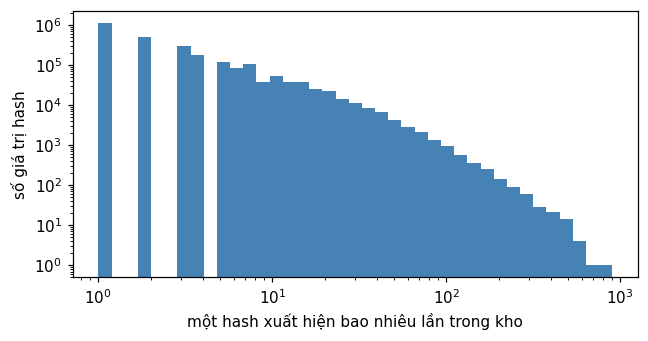

In [8]:
# Hash phổ biến đến mức nào? Đếm mỗi giá trị hash xuất hiện bao nhiêu lần trong cả kho.
_, bucket = np.unique(H, return_counts=True)
print(f"Số giá trị hash khác nhau: {len(bucket):,} (trên tối đa {2**24:,}) | tối đa một hash xuất hiện {bucket.max():,} lần")
print(f"Hash chỉ xuất hiện 1 lần: {100 * np.mean(bucket == 1):.0f}% | xuất hiện từ 10 lần: {100 * np.mean(bucket >= 10):.1f}% số giá trị hash")

fig, ax = plt.subplots(figsize=(6, 3.2))
ax.hist(bucket, bins=np.logspace(0, np.log10(bucket.max() + 1), 40), color="steelblue")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("một hash xuất hiện bao nhiêu lần trong kho"); ax.set_ylabel("số giá trị hash")
plt.tight_layout(); plt.show()

**Cách đọc:** đa số hash rất hiếm (chỉ vài bài có), nhưng cũng có những hash **phổ biến** xuất hiện hàng nghìn lần (thường là các cặp tần số thấp rất gần nhau, kiểu "tiếng bass đều"). Hash phổ biến khớp với rất nhiều bài nên **một mình nó chẳng nói lên gì**. Cách hệ thống xử lý chuyện này không phải là vứt chúng, mà là bước **bỏ phiếu theo độ lệch thời gian** ở phần sau: hit sai thì rải đều, hit đúng thì dồn về một chỗ.

---
## Phần 3 — Truy vấn: bỏ phiếu theo độ lệch thời gian

### 3.1. Ý tưởng

Với đoạn truy vấn, tính hash như thường (kèm thời điểm $t_q$ của từng hash **trong đoạn**). Tra từng hash vào chỉ mục, mỗi lần khớp cho ta một **hit**: (bài $b$, thời điểm $t_b$ của hash đó **trong bài**). Từ hit tính

$$\Delta = t_b - t_q$$

Nếu đoạn truy vấn thật sự cắt từ bài $b$, bắt đầu ở thời điểm $s$, thì **mọi hit đúng đều có cùng $\Delta = s$** (vì mỗi hash ở trong đoạn lệch so với trong bài đúng một khoảng $s$). Còn hit sai (hash trùng hợp, hoặc hash phổ biến) có $\Delta$ **rải ngẫu nhiên**. Do đó với mỗi bài ta đếm số hit rơi vào cùng một $\Delta$; **điểm của bài = số phiếu cao nhất ở một $\Delta$**. Bài điểm cao nhất thắng.

Bonus: $\Delta$ của người thắng cho biết **đoạn thu bắt đầu ở giây nào của bài**.

In [9]:
BIG = 4_000_000   # để gộp (mã bài, độ lệch) thành một số nguyên khi đếm


def match_hits(index, hq, tq):
    # Mọi hit: bài nào, thời điểm trong bài, thời điểm trong đoạn truy vấn.
    H, T, ID = index
    lo = np.searchsorted(H, hq, "left")
    hi = np.searchsorted(H, hq, "right")
    n = hi - lo                                              # mỗi hash truy vấn khớp bao nhiêu bản ghi
    total = int(n.sum())
    if total == 0:
        e = np.empty(0, np.int64)
        return e, e, e
    q_idx = np.repeat(np.arange(len(hq)), n)
    pos = np.arange(total) - np.repeat(np.cumsum(n) - n, n) + np.repeat(lo, n)
    return ID[pos].astype(np.int64), T[pos].astype(np.int64), tq[q_idx].astype(np.int64)


def search(index, hq, tq, top=3):
    # Trả về [(mã bài, điểm, độ lệch theo khung), ...] của `top` bài điểm cao nhất.
    tid, t_db, t_q = match_hits(index, hq, tq)
    if len(tid) == 0:
        return []
    delta = t_db - t_q
    key = tid * BIG + (delta + BIG // 2)
    uniq, votes = np.unique(key, return_counts=True)         # đếm phiếu cho từng (bài, độ lệch)
    order = np.argsort(-votes, kind="stable")
    uniq, votes = uniq[order], votes[order]
    tracks = uniq // BIG
    first_tracks, first = np.unique(tracks, return_index=True)   # lần đầu mỗi bài xuất hiện = phiếu cao nhất của bài đó
    best = np.argsort(-votes[first], kind="stable")[:top]
    return [(int(tracks[first[b]]), int(votes[first[b]]), int(uniq[first[b]] % BIG - BIG // 2)) for b in best]

### 3.2. Xem tận mắt một truy vấn

Lấy đoạn 5 s từ bài số 0 trong kho (bắt đầu giây 60), thêm ồn ở mức 10 dB, rồi tra. Ba hình dưới:
- **(a)** Mọi hit của đúng bài đó: trục ngang là thời điểm hash trong đoạn truy vấn, trục dọc là độ lệch $\Delta = t_b - t_q$. Hit đúng đều có $\Delta = s$, nên nằm trên **một đường ngang** (đường nét đứt là giây thật đã cắt). Hit sai nằm rải ở các mức khác.
- **(b)** Số phiếu theo $\Delta$ của bài đúng: có **một cột vọt cao** tại $\Delta = s$.
- **(c)** Cùng biểu đồ ấy cho bài sai mạnh nhất: thấp và rải đều.

Đoạn truy vấn: 275 hash | tra ra 2,516 hit trên 702 bài khác nhau
Bài thật: #0, đoạn bắt đầu ở 60.0 s (2584 khung)



,mã bài,điểm (số phiếu),độ lệch (khung),đoạn bắt đầu ở (s),đúng bài?
hạng,,,,,
1,0,40,2584,60.00,True
2,195,3,2335,54.22,False
3,149,2,7399,171.80,False


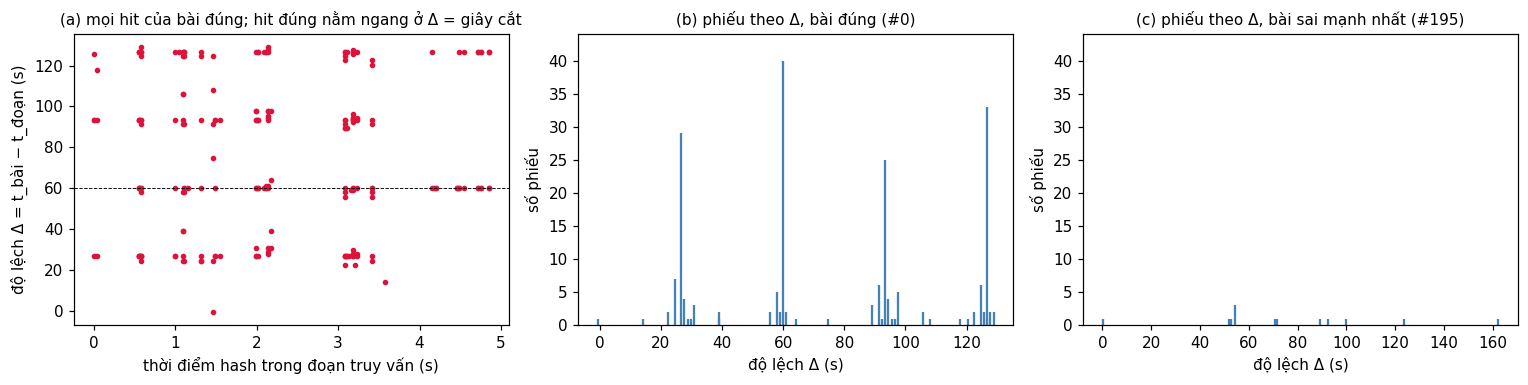

In [10]:
rng = np.random.default_rng(SEED)
true_idx, start = demo_idx, 60.0
y_q = add_noise(load_audio(CAT[true_idx], offset=start, duration=5), 10, rng)
h_q, t_q = fingerprint(y_q, **PARAMS)
tid, t_db, t_qq = match_hits(INDEX, h_q, t_q)
res = search(INDEX, h_q, t_q, top=3)

print(f"Đoạn truy vấn: {len(h_q)} hash | tra ra {len(tid):,} hit trên {len(np.unique(tid))} bài khác nhau")
print(f"Bài thật: #{true_idx}, đoạn bắt đầu ở {start:.1f} s ({start * SR / HOP:.0f} khung)\n")
display(pd.DataFrame([{"hạng": i + 1, "mã bài": r[0], "điểm (số phiếu)": r[1],
                       "độ lệch (khung)": r[2], "đoạn bắt đầu ở (s)": round(r[2] * HOP / SR, 2),
                       "đúng bài?": r[0] == true_idx} for i, r in enumerate(res)]).set_index("hạng"))

wrong = res[0][0] if res[0][0] != true_idx else res[1][0]
delta_s = (t_db - t_qq) * HOP / SR                           # độ lệch Δ tính bằng giây
fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
m = tid == true_idx
axes[0].scatter(t_qq[m] * HOP / SR, delta_s[m], s=7, c="crimson")
axes[0].axhline(start, color="k", lw=0.6, ls="--")
axes[0].set_xlabel("thời điểm hash trong đoạn truy vấn (s)"); axes[0].set_ylabel("độ lệch Δ = t_bài − t_đoạn (s)")
axes[0].set_title("(a) mọi hit của bài đúng; hit đúng nằm ngang ở Δ = giây cắt", fontsize=10)
ymax = 0
for ax, track, name in ((axes[1], true_idx, "(b) phiếu theo Δ, bài đúng"), (axes[2], wrong, "(c) phiếu theo Δ, bài sai mạnh nhất")):
    d, cnt = np.unique((t_db - t_qq)[tid == track], return_counts=True)
    ax.vlines(d * HOP / SR, 0, cnt, color="steelblue", lw=1.5)
    ax.set_xlabel("độ lệch Δ (s)"); ax.set_ylabel("số phiếu"); ax.set_title(f"{name} (#{track})", fontsize=10)
    ymax = max(ymax, cnt.max() if len(cnt) else 0)
for ax in axes[1:]:
    ax.set_ylim(0, ymax * 1.1)                               # cùng thang để so được
plt.tight_layout(); plt.show()

**Cách đọc:**
- Ở (b), cột cao nhất nằm đúng tại **Δ = giây đã cắt** (60 s), vượt xa bài sai. Đó là tín hiệu để nhận ra bài.
- Ở (b) còn có vài **cột phụ** ở các Δ khác. Lý do: bài này có các đoạn **lặp lại** (loop, kiểu nhạc điện tử), nên nội dung của đoạn truy vấn xuất hiện ở nhiều chỗ trong bài và cũng nhận phiếu ở các Δ tương ứng. Hệ thống vẫn chọn đúng cột cao nhất, nhưng biên độ giữa cột đúng và cột phụ không lớn. Đây chính là lý do ở phần 4 có một số truy vấn **đúng bài mà sai vị trí**.
- Ở (c), bài sai mạnh nhất chỉ có vài phiếu rải rác, nghĩa là hit sai thật sự **không tụ lại** ở một Δ nào. Khoảng cách giữa điểm bài đúng và điểm bài sai là thứ hệ thống dùng để quyết định; ta dùng đúng khoảng cách này để đặt **ngưỡng từ chối** ở phần 4.

**Quy tắc quyết định:** bài thắng là bài có điểm cao nhất. Muốn biết có nên tin hay không thì xét điểm đó có **vượt ngưỡng** $\theta$ không (đoạn quá ngắn, quá ồn, hay bài chưa có trong kho thì điểm thấp).

---
## Phần 4 — Thí nghiệm chính: chính xác tới đâu?

### 4.1. Thiết kế thí nghiệm

- **Truy vấn:** chọn ngẫu nhiên `N_QUERIES` bài trong kho; mỗi bài cắt một đoạn **bắt đầu ở một thời điểm ngẫu nhiên** (không canh theo khung nào cả). Cắt sẵn 10 s; đoạn 2 s và 5 s là phần đầu của chính đoạn 10 s đó, nên các độ dài **so sánh ghép cặp được**.
- **Điều kiện:** sạch, ồn trắng (10, 0, -5 dB), nén MP3, micro điện thoại, nhạc nền (10 và 3 dB). Mỗi điều kiện × mỗi độ dài.
- **Độ đo:** **top-1** = bài điểm cao nhất đúng là bài đã cắt. Kèm khoảng tin cậy 95% (Wilson), vì chỉ có `N_QUERIES` đoạn nên số đo có sai số lấy mẫu từ vài phần trăm (khi độ chính xác sát 100%) đến khoảng ±7 điểm phần trăm (khi quanh 50%).
- **Chú ý về dữ liệu sạch:** đoạn "sạch" được cắt từ **chính bản giải mã MP3 đã dùng để lập chỉ mục**, nên đây là trường hợp dễ nhất, kiểu "bản sao kỹ thuật số". Nó là mốc trên, không phải kết quả thực tế khi thu qua loa và micro.

In [11]:
def make_query_set(pool, n, max_len, seed, other_pool=None):
    # n đoạn dài max_len giây, mục tiêu nằm trong `pool` bài đầu của kho, kèm một đoạn "nhiễu nhạc nền" từ bài khác.
    rng = np.random.default_rng(seed)
    targets = rng.choice(pool, n, replace=n > pool)
    if other_pool is None:
        others = (targets + rng.integers(1, len(CAT), n)) % len(CAT)     # khác bài mục tiêu, lấy trong cả kho
    else:                                                                 # bài nhiễu cũng nằm trong kho nhỏ đang thử
        others = rng.integers(0, other_pool, n)
        others = np.where(others == targets, (others + 1) % other_pool, others)
    starts = rng.uniform(0, 1, n) * (DUR[targets] - max_len - 1)
    o_starts = rng.uniform(0, 1, n) * (DUR[others] - max_len - 1)
    pad = lambda y: np.pad(y, (0, max(0, int(max_len * SR) - len(y))))
    bases = Parallel(n_jobs=N_JOBS)(delayed(load_audio)(CAT[t], s, max_len) for t, s in zip(targets, starts))
    obases = Parallel(n_jobs=N_JOBS)(delayed(load_audio)(CAT[o], s, max_len) for o, s in zip(others, o_starts))
    return [pad(b) for b in bases], [pad(b) for b in obases], targets, starts


def run_queries(index, cond_fn, qset, length, params, seed):
    bases, others, targets, starts = qset
    n = int(length * SR)
    rng = np.random.default_rng(seed)
    rows = []
    for y0, o0, tg, st in zip(bases, others, targets, starts):
        y = cond_fn(y0[:n], o0[:n], rng)
        t0 = time.perf_counter()                                         # chỉ đo thời gian dấu vân tay + tra cứu
        h, t = fingerprint(y, **params)
        res = search(index, h, t)
        ms = 1000 * (time.perf_counter() - t0)
        ranked = [r[0] for r in res]
        rows.append(dict(correct=bool(ranked[:1] == [tg]), top2=bool(tg in ranked[:2]),
                         score=res[0][1] if res else 0, second=res[1][1] if len(res) > 1 else 0,
                         start_err=abs(res[0][2] * HOP / SR - st) if res and ranked[0] == tg else np.nan, ms=ms))
    return pd.DataFrame(rows)


def wilson(k, n, z=1.96):
    p = k / n
    d = 1 + z ** 2 / n
    c = p + z ** 2 / (2 * n)
    m = z * np.sqrt(p * (1 - p) / n + z ** 2 / (4 * n ** 2))
    return (c - m) / d, (c + m) / d


MAXQ = max(QUERY_LENGTHS)
main_qset = cached(f"qset_main_{len(CAT)}_{N_QUERIES}_{MAXQ}_{SEED}", lambda: make_query_set(len(CAT), N_QUERIES, MAXQ, SEED + 1))
MAIN_CONDS = [c for c in CONDITIONS if not c.startswith("tua")]
print(f"{len(main_qset[2])} đoạn truy vấn, {len(MAIN_CONDS)} điều kiện x {len(QUERY_LENGTHS)} độ dài = {len(MAIN_CONDS) * len(QUERY_LENGTHS)} thí nghiệm")

200 đoạn truy vấn, 8 điều kiện x 3 độ dài = 24 thí nghiệm


In [12]:
main_res = {}
t0 = time.time()
for ci, cname in enumerate(MAIN_CONDS):
    for L in QUERY_LENGTHS:
        key = f"main_c{ci}_L{L}_{len(CAT)}_{N_QUERIES}_{SEED}_{PARAMS_TAG}"
        main_res[(cname, L)] = cached(key, lambda: run_queries(INDEX, CONDITIONS[cname], main_qset, L, PARAMS, SEED + 100 * ci + L))
print(f"Xong ({time.time() - t0:.0f} s)")

acc = pd.DataFrame({L: {c: 100 * main_res[(c, L)]["correct"].mean() for c in MAIN_CONDS} for L in QUERY_LENGTHS})
acc.columns = [f"{L} s" for L in QUERY_LENGTHS]
print("Top-1 (%), bài đúng đứng đầu:")
display(acc.round(1))

Xong (0 s)
Top-1 (%), bài đúng đứng đầu:


,2 s,5 s,10 s
sạch,99.0,100.0,100.0
ồn 10 dB,72.0,91.0,96.5
ồn 0 dB,24.0,50.0,66.5
ồn -5 dB,3.5,17.5,35.0
nén MP3 (~30-40 kbps),98.5,100.0,100.0
micro điện thoại,98.0,100.0,100.0
nhạc nền 10 dB,80.0,82.0,82.5
nhạc nền 3 dB,61.0,63.0,63.0


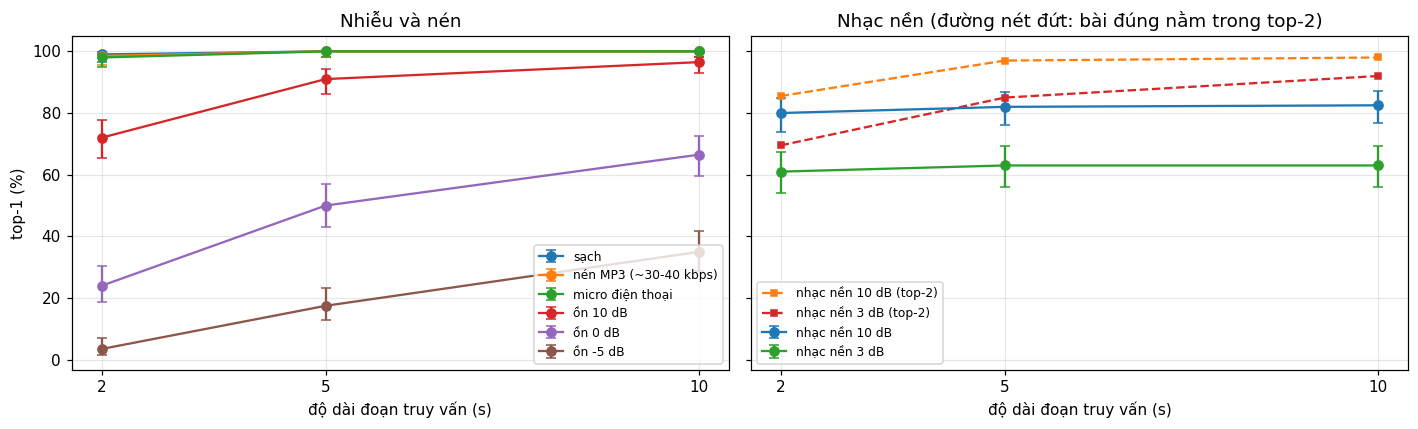

Với nhạc nền: bài đúng nằm trong top-2 (%):


,2 s,5 s,10 s
nhạc nền 10 dB,85.5,97.0,98.0
nhạc nền 3 dB,69.5,85.0,92.0


Điểm (số phiếu) trung vị của bài đứng đầu:


,2 s,5 s,10 s
sạch,34.0,94.5,186.5
ồn 10 dB,6.0,17.0,32.0
ồn 0 dB,3.0,3.5,6.0
ồn -5 dB,3.0,3.0,3.0
nén MP3 (~30-40 kbps),22.0,58.5,121.5
micro điện thoại,24.5,68.0,140.5
nhạc nền 10 dB,21.0,57.5,115.0
nhạc nền 3 dB,17.0,42.0,82.5


Khi đoán đúng bài: sai số vị trí bắt đầu đoạn có trung vị 6 ms (1 khung = 23 ms); 10.2% số lần đúng bài nhưng vị trí lệch hơn 0,1 s
Thời gian mỗi truy vấn (dấu vân tay + tra cứu, một nhân CPU): trung vị 4 ms


In [13]:
# Khoảng tin cậy và hình
fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
groups = [["sạch", "nén MP3 (~30-40 kbps)", "micro điện thoại", "ồn 10 dB", "ồn 0 dB", "ồn -5 dB"],
          ["nhạc nền 10 dB", "nhạc nền 3 dB"]]
for ax, names in zip(axes, groups):
    for c in names:
        k = [main_res[(c, L)]["correct"].sum() for L in QUERY_LENGTHS]
        p = np.array([100 * main_res[(c, L)]["correct"].mean() for L in QUERY_LENGTHS])
        ci = np.array([wilson(kk, len(main_res[(c, L)])) for kk, L in zip(k, QUERY_LENGTHS)]) * 100
        ax.errorbar(QUERY_LENGTHS, p, yerr=[p - ci[:, 0], ci[:, 1] - p], marker="o", capsize=3, label=c)
        if c.startswith("nhạc nền"):
            p2 = [100 * main_res[(c, L)]["top2"].mean() for L in QUERY_LENGTHS]
            ax.plot(QUERY_LENGTHS, p2, "--", marker="s", ms=4, label=c + " (top-2)")
    ax.set_xlabel("độ dài đoạn truy vấn (s)"); ax.set_xticks(QUERY_LENGTHS); ax.grid(alpha=0.3); ax.legend(fontsize=8)
axes[0].set_ylabel("top-1 (%)")
axes[0].set_title("Nhiễu và nén"); axes[1].set_title("Nhạc nền (đường nét đứt: bài đúng nằm trong top-2)")
plt.tight_layout(); plt.show()

top2 = pd.DataFrame({f"{L} s": {c: 100 * main_res[(c, L)]["top2"].mean() for c in ["nhạc nền 10 dB", "nhạc nền 3 dB"]} for L in QUERY_LENGTHS})
print("Với nhạc nền: bài đúng nằm trong top-2 (%):"); display(top2.round(1))
info = pd.DataFrame({f"{L} s": {c: main_res[(c, L)]["score"].median() for c in MAIN_CONDS} for L in QUERY_LENGTHS})
print("Điểm (số phiếu) trung vị của bài đứng đầu:"); display(info)
ok = pd.concat([main_res[(c, L)]["start_err"] for c in MAIN_CONDS for L in QUERY_LENGTHS]).dropna()
print(f"Khi đoán đúng bài: sai số vị trí bắt đầu đoạn có trung vị {1000 * ok.median():.0f} ms (1 khung = {1000 * HOP / SR:.0f} ms); "
      f"{100 * (ok > 0.1).mean():.1f}% số lần đúng bài nhưng vị trí lệch hơn 0,1 s")
tms = pd.concat([main_res[(c, L)]["ms"] for c in MAIN_CONDS for L in QUERY_LENGTHS])
print(f"Thời gian mỗi truy vấn (dấu vân tay + tra cứu, một nhân CPU): trung vị {tms.median():.0f} ms")

**Cách đọc (sẽ chốt lại ở cuối notebook):**
- Nhìn từng hàng từ trái sang phải: đoạn **dài hơn thì chính xác hơn**, vì có nhiều hash hơn để bỏ phiếu.
- **Nhiễu trắng** là thứ làm hỏng nhiều nhất: nó biến những ô vốn yên lặng thành đỉnh giả nên nhiều hash không còn khớp.
- **MP3** và **micro điện thoại** gần như không làm giảm top-1 (dù ở bảng 1.5 chỉ còn khoảng một nửa số hash): những đỉnh nổi bật vẫn sống sót qua nén và qua lọc dải, và một nửa số hash đã quá đủ để bỏ phiếu.
- **Nhạc nền:** top-1 có thể thấp hơn top-2 nhiều. Lý do không phải hệ thống "lỡ", mà là **cả hai bài đều có mặt trong âm thanh**, và hệ thống nhận ra bài nào có nhiều đỉnh nổi hơn. Nhìn đường nét đứt (top-2) để thấy cả hai bài thường đều bị nhận ra.

### 4.2. Bài lạ: khi bài không có trong kho

Ngoài đời, hệ thống thường nghe được bài **chưa có trong kho**. Nó vẫn trả về "bài điểm cao nhất", nhưng điểm sẽ thấp. Cần một **ngưỡng $\theta$**: điểm $\ge \theta$ thì tin, còn lại thì trả lời "không biết".

Ta lấy `N_QUERIES` đoạn 5 s từ các bài **ngoài kho**, tra bằng chỉ mục như cũ, ghi điểm của bài đứng đầu (chắc chắn là sai), rồi so với điểm của các truy vấn **trong kho** ở cùng điều kiện. Hai tình huống đối nghịch khi tăng $\theta$: nhận nhầm bài lạ giảm, nhưng bỏ sót bài đúng tăng.

Điều kiện 'sạch', đoạn 5 s (trong kho: 200 đoạn; bài lạ: 200 đoạn)


,trả lời ĐÚNG (%),trả lời SAI bài trong kho (%),nhận nhầm bài LẠ là có trong kho (%)
ngưỡng θ,,,
3,100.0,0.0,85.5
5,100.0,0.0,9.5
8,100.0,0.0,1.5
10,100.0,0.0,1.0
15,99.5,0.0,1.0
20,99.0,0.0,1.0
30,93.5,0.0,0.5
50,76.5,0.0,0.5


Điều kiện 'ồn 10 dB', đoạn 5 s (trong kho: 200 đoạn; bài lạ: 200 đoạn)


,trả lời ĐÚNG (%),trả lời SAI bài trong kho (%),nhận nhầm bài LẠ là có trong kho (%)
ngưỡng θ,,,
3,91.0,8.0,87.0
5,85.0,1.5,8.0
8,77.5,0.5,0.5
10,72.0,0.5,0.5
15,56.5,0.5,0.5
20,43.0,0.0,0.5
30,24.5,0.0,0.0
50,6.0,0.0,0.0


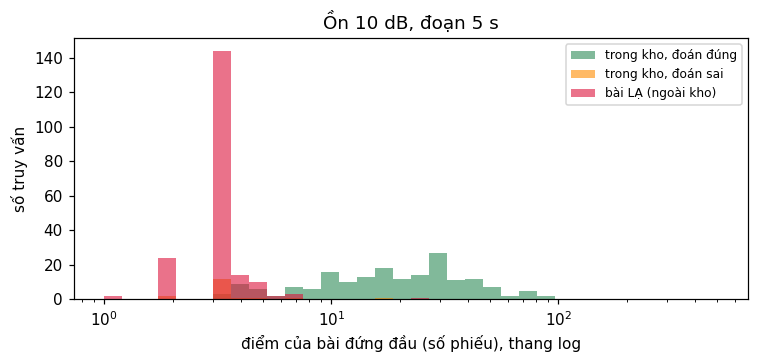

In [14]:
def make_unknown_set(n, length, seed):
    rng = np.random.default_rng(seed)
    pick = rng.choice(len(UNKNOWN), min(n, len(UNKNOWN)), replace=False)
    paths = [UNKNOWN[i] for i in pick]
    durs = [librosa.get_duration(path=p) for p in paths]
    starts = [rng.uniform(0, max(0.0, d - length - 1)) for d in durs]
    bases = Parallel(n_jobs=N_JOBS)(delayed(load_audio)(p, s, length) for p, s in zip(paths, starts))
    pad = lambda y: np.pad(y, (0, max(0, int(length * SR) - len(y))))
    bases = [pad(b) for b in bases]
    return bases, bases, np.full(len(bases), -1), np.array(starts)          # mục tiêu = -1: không bao giờ "đúng"


unk_qset = cached(f"qset_unknown_{len(UNKNOWN)}_{N_QUERIES}_{SEED}", lambda: make_unknown_set(N_QUERIES, 5, SEED + 2))
unk_res = {}
for ci, cname in enumerate(["sạch", "ồn 10 dB"]):
    unk_res[cname] = cached(f"unk_{ci}_{len(CAT)}_{N_QUERIES}_{SEED}_{PARAMS_TAG}",
                            lambda: run_queries(INDEX, CONDITIONS[cname], unk_qset, 5, PARAMS, SEED + 300 + ci))

THETAS = [3, 5, 8, 10, 15, 20, 30, 50]
for cname in ["sạch", "ồn 10 dB"]:
    known_r, unk_r = main_res[(cname, 5)], unk_res[cname]
    rows = [{"ngưỡng θ": th,
             "trả lời ĐÚNG (%)": 100 * (known_r["correct"] & (known_r["score"] >= th)).mean(),
             "trả lời SAI bài trong kho (%)": 100 * (~known_r["correct"] & (known_r["score"] >= th)).mean(),
             "nhận nhầm bài LẠ là có trong kho (%)": 100 * (unk_r["score"] >= th).mean()} for th in THETAS]
    print(f"Điều kiện '{cname}', đoạn 5 s (trong kho: {len(known_r)} đoạn; bài lạ: {len(unk_r)} đoạn)")
    display(pd.DataFrame(rows).set_index("ngưỡng θ").round(1))

fig, ax = plt.subplots(figsize=(7, 3.4))
bins = np.logspace(0, 2.7, 35)
ax.hist(np.clip(main_res[("ồn 10 dB", 5)].query("correct")["score"], 1, None), bins=bins, alpha=0.6, label="trong kho, đoán đúng", color="seagreen")
ax.hist(np.clip(main_res[("ồn 10 dB", 5)].query("not correct")["score"], 1, None), bins=bins, alpha=0.6, label="trong kho, đoán sai", color="darkorange")
ax.hist(np.clip(unk_res["ồn 10 dB"]["score"], 1, None), bins=bins, alpha=0.6, label="bài LẠ (ngoài kho)", color="crimson")
ax.set_xscale("log"); ax.set_xlabel("điểm của bài đứng đầu (số phiếu), thang log"); ax.set_ylabel("số truy vấn")
ax.set_title("Ồn 10 dB, đoạn 5 s"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

**Cách đọc:** điểm của bài lạ dồn về **mức thấp** (vài phiếu, ngang với "trùng hợp"), còn điểm của truy vấn đoán đúng **cao hơn hẳn**; vùng chồng lấn nhỏ, nên chọn được một ngưỡng $\theta$ làm nhận nhầm bài lạ gần như bằng 0 mà vẫn giữ phần lớn câu trả lời đúng. Giá phải trả là **bỏ sót** những truy vấn đúng nhưng điểm thấp (đoạn ngắn, ồn nhiều). Chọn $\theta$ là chọn điểm cân bằng: ứng dụng nào sợ trả lời sai thì đặt cao.

### 4.3. Giới hạn: đổi tốc độ

Hash chứa **tần số tuyệt đối** và **khoảng cách thời gian tuyệt đối**. Nếu bài bị phát nhanh hơn $x\%$ thì mọi tần số nhân lên và mọi khoảng cách co lại, nên hash đổi hết. Thử với các mức đổi tốc độ khác nhau (đoạn 5 s, cùng bộ truy vấn):

tốc độ so với gốc (%),-5.0,-2.0,-1.0,-0.5,0.0,0.5,1.0,2.0,5.0
top-1 (%),0.5,1.0,9.5,72.5,100.0,77.5,12.5,0.0,0.0


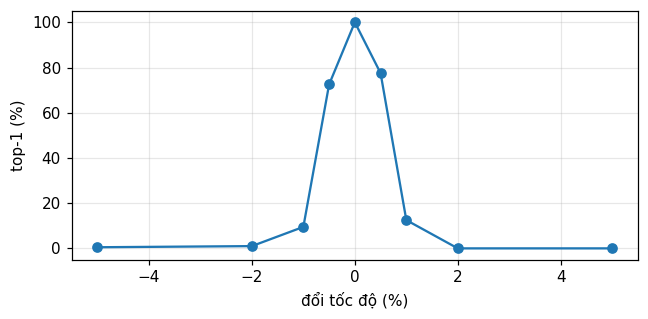

In [15]:
SPEEDS = [0.95, 0.98, 0.99, 0.995, 1.0, 1.005, 1.01, 1.02, 1.05]
speed_acc = []
for si, f in enumerate(SPEEDS):
    key = f"speed_{si}_{len(CAT)}_{N_QUERIES}_{SEED}_{PARAMS_TAG}"
    r = cached(key, lambda: run_queries(INDEX, lambda y, o, rg: change_speed(y, f) if f != 1.0 else y, main_qset, 5, PARAMS, SEED + 400 + si))
    speed_acc.append(100 * r["correct"].mean())
sp = pd.DataFrame({"tốc độ so với gốc (%)": [round(100 * (f - 1), 1) for f in SPEEDS], "top-1 (%)": np.round(speed_acc, 1)}).set_index("tốc độ so với gốc (%)")
display(sp.T)

fig, ax = plt.subplots(figsize=(6, 3))
ax.plot([100 * (f - 1) for f in SPEEDS], speed_acc, "-o")
ax.set_xlabel("đổi tốc độ (%)"); ax.set_ylabel("top-1 (%)"); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

**Cách đọc:** chỉ cần lệch vài phần trăm tốc độ là độ chính xác **sụp** (chỉ lệch nửa phần trăm cũng bắt đầu mất vì khoảng cách thời gian $\Delta t$ tính theo khung nguyên bị lệch). Đây là điểm yếu có thật của hướng "hash tuyệt đối": Shazam bản chính vẫn xử lý được vì dùng thêm các mẹo khác (và đoạn thu thực tế hiếm khi bị đổi tốc độ). Ta nói được điểm yếu này rõ ràng, đây là điều quan trọng khi vấn đáp.

---
## Phần 5 — Tham số nào quan trọng? (ablation)

Thuật toán có nhiều "núm vặn". Ta **vặn từng núm một** (giữ các núm khác ở mặc định) rồi đo lại. Để chạy nhanh, dùng kho nhỏ **300 bài** và 100 đoạn truy vấn 5 s, ở hai điều kiện khó vừa phải: **ồn 10 dB** và **nhạc nền 10 dB** (top-1). Mỗi cấu hình phải dựng lại chỉ mục từ đầu.

| Núm | Ý nghĩa | Vặn thế nào |
|---|---|---|
| vùng lân cận `nf`×`nt` | càng rộng, đỉnh càng **thưa** | 15×31 / **21×41** / 31×61 |
| `floor` | đỉnh phải cao hơn ngưỡng dB này mới giữ | **0** / 10 / 20 |
| `K` | mỗi đỉnh ghép với `K` đỉnh kế tiếp (nhiều hash hơn) | 2 / **5** / 10 |
| `dt_max` | hai đỉnh trong cặp cách nhau tối đa bao nhiêu khung | 15 / 31 / **63** |

Đậm là giá trị mặc định. Với chỉ 100 truy vấn, khoảng tin cậy rộng cỡ ±6 đến 10 điểm phần trăm; **chỉ tin những chênh lệch lớn**.

,hash/giây nhạc,chỉ mục (MB),top-1 ồn 10 dB (%),top-1 nhạc nền 10 dB (%),ms/truy vấn
mặc định,47.6,38.4,95.0,83.0,3.5
lân cận nhỏ 15x31,77.8,62.8,97.0,85.0,4.2
lân cận lớn 31x61,24.1,19.5,98.0,84.0,4.0
floor 10 dB,45.7,36.8,98.0,86.0,4.8
floor 20 dB,41.1,33.2,96.0,87.0,4.5
K=2,16.0,12.9,82.0,86.0,4.2
K=10,103.3,83.4,98.0,83.0,4.5
dt_max=15,39.6,31.9,94.0,83.0,4.1
dt_max=31,46.6,37.6,96.0,83.0,5.3


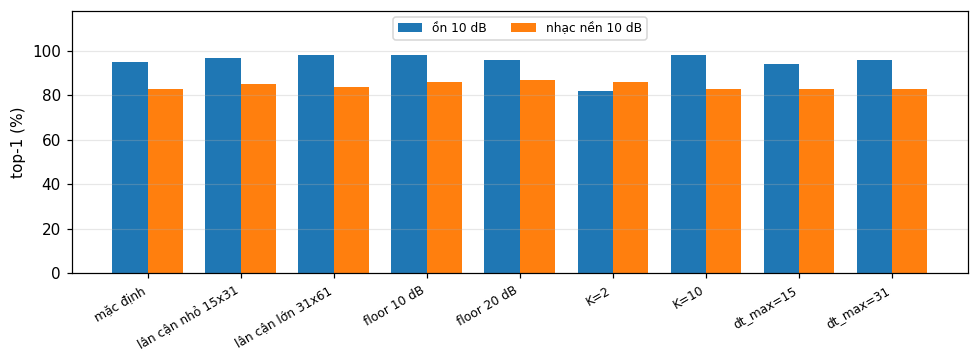

In [16]:
ABL_POOL = min(300, len(CAT))
abl_qset = cached(f"qset_abl2_{ABL_POOL}_{SEED}", lambda: make_query_set(ABL_POOL, 100, 5, SEED + 11, other_pool=ABL_POOL))
ABL_CONFIGS = {
    "mặc định": {},
    "lân cận nhỏ 15x31": dict(nf=15, nt=31), "lân cận lớn 31x61": dict(nf=31, nt=61),
    "floor 10 dB": dict(floor=10.0), "floor 20 dB": dict(floor=20.0),
    "K=2": dict(K=2), "K=10": dict(K=10),
    "dt_max=15": dict(dt_max=15), "dt_max=31": dict(dt_max=31),
}
ABL_CONDS = ["ồn 10 dB", "nhạc nền 10 dB"]


def run_ablation(over, ai):
    params = {**PARAMS, **over}
    t0 = time.time()
    idx = build_index(CAT[:ABL_POOL], params)
    build = time.time() - t0
    out = dict(hash_per_s=len(idx[0]) / DUR[:ABL_POOL].sum(), index_mb=sum(a.nbytes for a in idx) / 1e6, build_s=build)
    ms = []
    for cname in ABL_CONDS:
        r = run_queries(idx, CONDITIONS[cname], abl_qset, 5, params, SEED + 500 + ai)
        out[cname] = 100 * r["correct"].mean()
        ms.append(r["ms"].median())
    out["ms"] = float(np.mean(ms))                                       # giữ "ms" ở cuối để khớp tên cột bên dưới
    return out


abl_rows = {}
for ai, (name, over) in enumerate(ABL_CONFIGS.items()):
    abl_rows[name] = cached(f"abl2_{ai}_{ABL_POOL}_{SEED}_{PARAMS_TAG}", lambda: run_ablation(over, ai))
abl = pd.DataFrame(abl_rows).T
abl.columns = ["hash/giây nhạc", "chỉ mục (MB)", "dựng chỉ mục (s)", "top-1 ồn 10 dB (%)", "top-1 nhạc nền 10 dB (%)", "ms/truy vấn"]
abl = abl.drop(columns=["dựng chỉ mục (s)"])          # bỏ cột thời gian dựng: đo trên máy dùng chung nhiều tiến trình nên nhiễu
display(abl.round(1))

fig, ax = plt.subplots(figsize=(9, 3.4))
x = np.arange(len(abl)); w = 0.38
ax.bar(x - w / 2, abl["top-1 ồn 10 dB (%)"], w, label="ồn 10 dB")
ax.bar(x + w / 2, abl["top-1 nhạc nền 10 dB (%)"], w, label="nhạc nền 10 dB")
ax.set_xticks(x); ax.set_xticklabels(abl.index, rotation=30, ha="right", fontsize=8)
ax.set_ylabel("top-1 (%)"); ax.set_ylim(0, 118); ax.legend(fontsize=8, ncol=2, loc="upper center"); ax.grid(axis="y", alpha=0.3)
plt.tight_layout(); plt.show()

**Cách đọc:** cột "hash/giây nhạc" và "chỉ mục (MB)" cho thấy **cái giá** của mỗi cấu hình (kích thước bảng tra và thời gian tra); hai cột top-1 cho thấy **cái lợi**. Núm nào làm top-1 đổi nhiều mà giá lại rẻ thì đáng chú ý. Núm nào chỉ làm chỉ mục to lên mà chính xác không đổi (trong phạm vi sai số) thì không đáng. Đừng suy diễn từ chênh lệch nhỏ.

---
## Phần 6 — Kho lớn dần thì sao?

Kho càng nhiều bài thì càng nhiều hash **trùng hợp**, nên điểm của bài sai cao dần, còn điểm của bài đúng giữ nguyên. Đo trực tiếp: dùng cùng một chỉ mục toàn bộ nhưng **chỉ giữ lại các bản ghi của `n` bài đầu** (cắt mảng theo mã bài, chính xác như dựng chỉ mục nhỏ hơn), rồi truy vấn **cùng bộ đoạn** (đều từ 50 bài đầu nên có mặt ở mọi cỡ kho). Điều kiện hơi khó để thấy xu hướng: **ồn 10 dB, đoạn 3 s**.

,số hash (triệu),top-1 (%),điểm trung vị bài đúng,điểm trung vị bài sai,ms/truy vấn
số bài trong kho,,,,,
50,0.55,88.0,11.0,1.0,2.70
100,1.09,88.0,11.0,1.5,2.54
250,2.64,86.0,11.5,2.0,2.51
500,5.21,85.0,12.0,2.0,2.51
750,7.75,85.0,12.0,3.0,2.60
1020,10.67,84.0,12.0,3.0,2.67


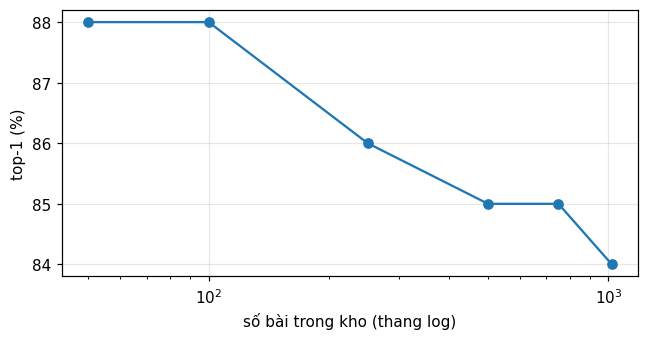

In [17]:
SIZES = sorted({s for s in (50, 100, 250, 500, 750) if s < len(CAT)} | {len(CAT)})
POOL_SC = min(50, len(CAT))
sc_qset = cached(f"qset_scale_{POOL_SC}_{SEED}", lambda: make_query_set(POOL_SC, 100, 3, SEED + 22))


def run_scaling():
    rows = {}
    for size in SIZES:
        mask = ID < size
        sub = (H[mask], T[mask], ID[mask])
        r = run_queries(sub, CONDITIONS["ồn 10 dB"], sc_qset, 3, PARAMS, SEED + 600)
        rows[size] = {"số hash (triệu)": len(sub[0]) / 1e6, "top-1 (%)": 100 * r["correct"].mean(),
                      "điểm trung vị bài đúng": r.query("correct")["score"].median(),
                      "điểm trung vị bài sai": r.query("not correct")["score"].median() if (~r["correct"]).any() else np.nan,
                      "ms/truy vấn": r["ms"].median()}
    return pd.DataFrame(rows).T


scal = cached(f"scale_{len(CAT)}_{SEED}_{PARAMS_TAG}", run_scaling)
scal.index.name = "số bài trong kho"
display(scal.round(2))

fig, ax = plt.subplots(figsize=(6, 3.2))
ax.plot(scal.index, scal["top-1 (%)"], "-o"); ax.set_xscale("log")
ax.set_xlabel("số bài trong kho (thang log)"); ax.set_ylabel("top-1 (%)"); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

**Cách đọc:** quan sát cột top-1 và cột "điểm trung vị bài sai" khi kho tăng từ 50 lên cả nghìn bài, rồi tự hỏi: Shazam thật có hàng chục triệu bài thì sao? Cách họ làm nó chạy được là hash **đặc trưng hơn** (nhiều bit hơn) và đoạn truy vấn đủ dài để điểm bài đúng vượt xa nền trùng hợp. Kho của ta quá nhỏ để rút ra kết luận về quy mô lớn; phần này chỉ cho thấy **chiều hướng**.

---
## Phần 7 — Thử trọn vẹn một ví dụ

Hàm `identify` nhận một đoạn âm thanh bất kỳ và trả về các bài khớp nhất kèm vị trí. Ta thử với một đoạn **6 s**, vừa thêm **ồn 10 dB** vừa **nén MP3**, rồi trộn hai bài cùng lúc để xem hệ thống nhận ra cả hai không.

In [18]:
def identify(y, index=INDEX, top=3):
    h, t = fingerprint(y, **PARAMS)
    return [dict(bài=CAT[tid].name, mã=tid, điểm=score, giây_trong_bài=round(off * HOP / SR, 1))
            for tid, score, off in search(index, h, t, top)]


rng = np.random.default_rng(SEED + 7)
tr = int(rng.integers(len(CAT)))
st = float(rng.uniform(0, DUR[tr] - 8))
y6 = load_audio(CAT[tr], offset=st, duration=6)
y6_bad = mp3_roundtrip(add_noise(y6, 10, rng))[0]

print(f"SỰ THẬT: bài #{tr} ({CAT[tr].name}), đoạn thu bắt đầu ở giây {st:.1f}")
print("\n1) Đoạn 6 s, ồn 10 dB + nén MP3:")
display(pd.DataFrame(identify(y6_bad)))

tr2 = (tr + 1 + int(rng.integers(len(CAT) - 1))) % len(CAT)
st2 = float(rng.uniform(0, DUR[tr2] - 8))
y_other = load_audio(CAT[tr2], offset=st2, duration=6)
print(f"\n2) Trộn hai bài cùng lúc: #{tr} (giây {st:.1f}) và #{tr2} (giây {st2:.1f}), mức 3 dB:")
display(pd.DataFrame(identify(mix_music(y6, y_other, 3), top=3)))

SỰ THẬT: bài #963 (982407.low.mp3), đoạn thu bắt đầu ở giây 140.9

1) Đoạn 6 s, ồn 10 dB + nén MP3:


,bài,mã,điểm,giây_trong_bài
0,982407.low.mp3,963,10,140.9
1,1328507.low.mp3,61,3,210.9
2,1374303.low.mp3,78,3,126.1



2) Trộn hai bài cùng lúc: #963 (giây 140.9) và #580 (giây 88.8), mức 3 dB:


,bài,mã,điểm,giây_trong_bài
0,230905.low.mp3,580,48,88.8
1,982407.low.mp3,963,8,140.9
2,1328507.low.mp3,61,3,210.9


---
## Tổng kết

Các số dưới đây lấy từ lần chạy này (kho 1.020 bài, 200 đoạn truy vấn mỗi thí nghiệm chính, `SEED = 0`); chạy lại trên máy khác có thể lệch vài điểm phần trăm.

**Hệ thống nhận ra bài rất tốt khi âm thanh còn "sạch":**
- Đoạn **5 s** nhận đúng **100%** khi sạch, khi nén MP3 (~40 kbps) và khi lọc như micro điện thoại. Đoạn **2 s** vẫn đạt **98 đến 99%**.
- Một truy vấn (dấu vân tay + tra cứu) mất khoảng **4 ms** trên một nhân CPU, và vị trí bắt đầu đoạn thu được ước lượng với sai số trung vị chỉ **6 ms**.
- Chỉ mục cho 62 giờ nhạc: **10,7 triệu hash, 128 MB**, dựng trong khoảng 80 giây trên 4 nhân.

**Điểm yếu thật, theo thứ tự nặng dần:**
1. **Nhiễu trắng mạnh.** Top-1 ở đoạn 5 s: **91%** (10 dB), **50%** (0 dB), **17,5%** (-5 dB). Đoạn dài hơn cải thiện rõ (10 s ở 0 dB: 66,5%) vì có nhiều hash để bỏ phiếu hơn.
2. **Có bài khác phát cùng lúc.** Với nhạc nền 10 dB, top-1 chỉ khoảng **82%** nhưng bài đúng nằm trong top-2 tới **97%** (đoạn 5 s): hệ thống nhận ra *cả hai* bài, và chọn bài có nhiều đỉnh nổi hơn. Đây là hiện tượng đúng, không phải lỗi.
3. **Đổi tốc độ.** Lệch ±0,5% còn khoảng 72 đến 78%, lệch **1%** chỉ còn 9 đến 13%, lệch **2% trở lên gần như 0%**. Hash dựa trên tần số và khoảng cách thời gian *tuyệt đối*.
4. **Đoạn lặp lại trong bài:** khoảng **10%** số lần nhận đúng bài nhưng chỉ ra sai vị trí (> 0,1 s), vì nhạc điện tử hay lặp loop giống hệt, nên cùng bài có nhiều vị trí khớp.

**Bài lạ (ngoài kho):** điểm của bài đứng đầu thấp. Ngưỡng $\theta \approx 8$ đến $10$ phiếu làm nhận nhầm bài lạ chỉ còn **0,5 đến 1,5%** nhưng vẫn giữ **100%** câu trả lời đúng khi sạch và **72 đến 78%** khi ồn 10 dB (đoạn 5 s). Đặt $\theta = 3$ thì khoảng 85 đến 87% bài lạ bị nhận nhầm: ngưỡng quá thấp là vô nghĩa.

**Tham số nào đáng quan tâm (kho 300 bài, 100 truy vấn, chênh dưới khoảng 5 điểm là chưa kết luận được):**
- **`K` (số cặp mỗi đỉnh)** là núm rõ nhất: `K = 2` tụt từ 95% xuống **82%** ở ồn 10 dB; `K = 10` lên 98% nhưng chỉ mục to gấp 2,2 lần.
- **Mật độ đỉnh** (vùng lân cận) chủ yếu đổi **kích thước chỉ mục** (63 MB, 38 MB, 20 MB cho 15×31, 21×41, 31×61) mà độ chính xác không đổi rõ (97%, 95%, 98%). Đỉnh thưa nghĩa là rẻ hơn mà không mất nhiều.
- `floor`, `dt_max`: không thấy khác biệt vượt sai số.
- Điều kiện nhạc nền hầu như **không phụ thuộc tham số** (83 đến 87% ở mọi cấu hình): giới hạn nằm ở chỗ "có hai bài trong âm thanh", không phải ở cách chỉnh.

**Kho lớn dần (ồn 10 dB, đoạn 3 s):** top-1 giảm nhẹ từ **88%** (50 bài) xuống **84%** (1.020 bài), nằm trong sai số của 100 truy vấn; nhưng điểm trung vị của bài **sai** tăng đều từ 1 lên 3 phiếu trong khi điểm bài đúng giữ khoảng 11 đến 12. Đúng chiều hướng dự đoán: kho lớn thì nền "trùng hợp" cao lên. Thời gian tra gần như không đổi (~2,5 ms).

**Một câu để nhớ:** đoạn càng dài và càng sạch thì bỏ phiếu càng áp đảo, còn hai thứ phá hệ thống là *nhiễu quá mạnh* và *làm lệch thang tần số/thời gian* (đổi tốc độ).

---
## So sánh với notebook 02

| | Notebook 02: đoán mood | Notebook 03: nhận diện bài |
|---|---|---|
| Ý tưởng | **nén cả đoạn** thành 93 số, để mô hình học ranh giới giữa các nhóm | **giữ vài điểm nổi bật**, biến thành mã, tra bảng |
| Học máy | có; kết quả phụ thuộc mô hình và cách chia dữ liệu | không; kết quả phụ thuộc tham số và độ dài đoạn |
| Đánh giá | khó: nhãn chủ quan, phải chia theo artist, so với nhiều baseline | dễ: đúng hay sai bài, đo trực tiếp |
| Hiểu được vì sao đúng/sai | hạn chế (hệ số mô hình, ablation nhóm đặc trưng) | rõ: nhìn thẳng vào phiếu bầu |
| Hợp khi | cần *khái quát* sang bài chưa từng thấy | cần *khớp chính xác* với bài đã biết |
| Điểm yếu lớn | độ chính xác vừa phải, nhãn mơ hồ | không khái quát: bài mới, bản cover, đổi tốc độ là mất |

Nói ngắn gọn: **notebook 02 trả lời "bài này nghe giống cái gì"**, **notebook 03 trả lời "bài này chính xác là bài nào"**. Hai bài toán cùng xuất phát từ spectrogram nhưng cần hai cách nghĩ khác nhau.

## Hạn chế cần nói thật khi vấn đáp

- **Kho nhỏ:** 1.020 bài, trong khi hệ thống thật có hàng chục triệu. Ta chỉ thấy *chiều hướng* khi kho lớn dần, chưa chứng minh được ở quy mô lớn.
- **Đoạn "sạch" là bản sao kỹ thuật số** của đúng bản đã lập chỉ mục. Thực tế còn tiếng vang phòng, loa, micro, mất gói; ồn trắng và lọc dải chỉ là **mô phỏng** đơn giản của chúng.
- **Chỉ có bài gốc trong kho:** bản live, bản remix, bản cover, đổi tông là bài toán khác (kể cả dùng hướng của Shazam thì cũng không nhận ra).
- **Bản đơn giản hóa:** cách ghép cặp (K đỉnh kế tiếp), hash 24 bit, không xử lý dịch khung thời gian bằng phép dung sai; bản Shazam thật khác nhiều chi tiết.
- **Số truy vấn có hạn** (`N_QUERIES` = 200 cho thí nghiệm chính, 100 cho ablation), nên chênh lệch nhỏ giữa hai cấu hình **không đủ kết luận**.
- **Trùng lặp trong dữ liệu:** Jamendo có thể chứa các bài rất giống nhau (cùng bản thu đăng ở hai album); nếu có, một số "đoán sai" thật ra là hai bản gần như trùng.
- Kết quả phụ thuộc phiên bản thư viện (librosa, soundfile/libsndfile khi nén MP3, SciPy), nên số có thể lệch vài điểm phần trăm trên máy khác.

## Tự thử (rất nên làm)

1. Đổi `PARAMS["K"]` từ 5 lên 10 rồi chạy lại phần 2 và 4. Chỉ mục to ra bao nhiêu? Top-1 ở đoạn 2 s tăng bao nhiêu? Có đáng không?
2. Đổi `N_FFT` hoặc `HOP` (phần cấu hình). Điều gì xảy ra với số hash/giây và với độ chính xác khi có ồn? Giải thích bằng $\Delta f = f_s / N$ (notebook 01).
3. Thêm một điều kiện **tắt tiếng một nửa đoạn** (nhân 0 nửa sau) và đoán trước kết quả trước khi chạy.
4. Cắt đoạn **1 s**: top-1 còn bao nhiêu? Vì sao?
5. Vẽ lại hình (b) ở phần 3.2 cho một truy vấn **đoán sai**. Cột cao nhất của bài sai so với bài đúng thế nào?
6. Nghĩ cách làm hash **chịu được đổi tốc độ** (gợi ý: dùng *tỷ lệ* $f_2/f_1$ và $\Delta t$ chia cho một đại lượng cùng đổi theo).